# The Bellman factory on the Benhabib–Bisin–Luo model

<div class="alert alert-info">

**Summary**

This lesson reads the within-life model of Benhabib, Bisin and Luo from its registry into the model as written, binds a stage at every position, draws the result, changes it by a fill and a sweep, and builds two periods by hand. The object inspected is the [[trellis]]. The lesson constructs and binds; it solves nothing.

</div>

<div class="alert alert-success">

**Relationship with other documents**

**Builds on** — [Periods and trellises](../../getting-started/05-periods-and-trellises.ipynb): periods, trellises and the trellis verbs.

**See also** — [The Bellman factory](../../../docs/Bellman-Sym/08-bellman-factory.md): the calls this lesson makes; [the model's account](../../../applications/benhabib-2019/economics.md): the model and its files.

</div>

<div class="alert">

**Key terminology**

| Term | Meaning |
|---|---|
| Bellman factory | The part of the package that takes a model from its registry to a specified trellis, by `load_recipe`, `elaborate_trellis`, the three binding verbs and `accrete`; `assemble_trellis` returns in one call the trellis those calls make. |
| registry | A folder holding a model's stage files, parameter values, methods, settings, period template (`period.yml`, listing the stages a period holds), trellis file and recipe. |
| [[spec_factory\|recipe]] | The file naming, for each stage and kind of binding, the files its mapping is merged from. |
| syntactic trellis | The model as written, with records of files in place of stages. |
| fill | A dictionary bound to a slot of the recipe. |
| sweep | A family of trellises, one for each fill. |

</div>

A household with a fixed earnings type and a fixed return type consumes and saves at each age of its working life and leaves its remaining wealth as a bequest: the within-life problem of Benhabib, Bisin and Luo (2019), "Wealth distribution and social mobility in the US: A quantitative approach", *American Economic Review* 109(5), 1623–1647. At each age the household enters the decision with its wealth $\mathrm m$ and chooses consumption $\mathrm c \in [0, \mathrm m]$; its saving earns the gross return $R_r$ of its type $r$, and the earnings $w_\tau$ of its decile $\tau$ in the age bracket are then paid, so that $\mathrm a = R_r(\mathrm m - \mathrm c) + w_\tau$. Utility is $u(\mathrm c) = \mathrm c^{1-\sigma}/(1-\sigma)$, discounted by $\beta$. After the last decision, a terminal period holds a second [[stage]], the bequest, which values the wealth left by the warm glow $e(\mathrm a) = A\,\mathrm a^{1-\mu}/(1-\mu)$.

| In the file | Symbol | Meaning |
|---|---|---|
| `m`, `a` | $\mathrm m$, $\mathrm a$ | wealth at the decision and at the continuation |
| `a_pre` | $\mathrm a_{\mathrm{pre}}$ | the wealth with which the bequest arrives |
| `c` | $\mathrm c$ | consumption |
| `V`, `D_{m}V` | $V$, $D_m V$ | the value and its derivative in the state |
| `tau`, `wage_fn` | $\tau$, $w$ | the decile, `q1` to `q10`, and each decile's earnings |
| `r_type`, `R_vec` | $r$, $R$ | the return type, `r1` to `r5`, and each type's gross return |
| `β`, `σ`, `A`, `μ` | $\beta$, $\sigma$, $A$, $\mu$ | the discount factor, the curvature of utility, the bequest's weight and curvature |


The lesson reads the registry's files, given by their paths from the repository root:

- `applications/benhabib-2019/declaration/spec.yml`
- `applications/benhabib-2019/declaration/trellis.yml`
- `applications/benhabib-2019/declaration/period.yml`
- `applications/benhabib-2019/declaration/stages/benhabib_bellman/benhabib_bellman.bl`
- `applications/benhabib-2019/declaration/stages/bequest/bequest.bl`
- `applications/benhabib-2019/declaration/calibration/main.yml`
- `applications/benhabib-2019/declaration/calibration/horizon.yml`
- `applications/benhabib-2019/declaration/calibration/wage/bracket_1.yml`
- `applications/benhabib-2019/declaration/calibration/wage/bracket_2.yml`
- `applications/benhabib-2019/declaration/calibration/wage/bracket_3.yml`
- `applications/benhabib-2019/declaration/calibration/wage/bracket_4.yml`
- `applications/benhabib-2019/declaration/calibration/wage/bracket_5.yml`
- `applications/benhabib-2019/declaration/calibration/wage/bracket_6.yml`
- `applications/benhabib-2019/declaration/stages/benhabib_bellman/methods.yml`
- `applications/benhabib-2019/declaration/settings/default.yml`

It writes no file. The first code cell imports the collection's set-up module, checkout, which makes the package importable, sets the working directory to the repository root and defines one function, explore, which opens the interactive view of a stage or a trellis in Google's Model Explorer and which this lesson does not call; the cell then imports the functions the lesson calls, from bellman.stage, bellman.period and bellman.trellis.

In [1]:
import checkout
from bellman.period import diagram_period
from bellman.stage import elaborate_stage, load_stage
from bellman.trellis import (
    accrete,
    assemble_trellis,
    calibrate_trellis,
    changed_positions,
    configure_trellis,
    connection_report,
    diagram_trellis,
    elaborate_trellis,
    load_recipe,
    methodize_trellis,
)

## The recipe and the model as written

The [[spec_factory|recipe]] names, for each stage and kind of binding, an ordered list of **sources**, files named without their extension, and **slots**, `$fill` and `$bellman_method`, which take a dictionary when one is given:

In [2]:
print(open("applications/benhabib-2019/declaration/spec.yml").read())

# The recipe of the within-life model of Benhabib, Bisin and Luo (2019): the
# trellis file and each stage's file, by their paths from this folder, and for
# each stage and each kind the ordered sources; `$fill` and the methods slot
# `$bellman_method` are bound by keyword of `load_recipe`.
#
# periods[0] is the terminal period and holds the bequest alone,
# `periods: [0, 0]`; periods[1] to periods[36] hold the within-life stage, ages
# 60 to 25 (calibration/horizon.yml). Earnings are constant within each of six
# age brackets of six years, and each range list supplies the bracket's whole
# `wage_fn`: "1-6" holds ages 60 to 55, the sixth bracket, and "31-36" ages 30
# to 25, the first (economics.md, "The age brackets"). A range source is applied
# after `$fill` and overrides it, so a `wage_fn` in a fill is replaced by the
# bracket's file. The bequest's one methods file binds the marginal block of
# its derivative, which the endogenous grid step of the last age reads.
trellis: trellis.

The within-life stage stands in `periods: [1, 36]`, the bequest in `[0, 0]`, counted back from the terminal period; the **range keys** `"1-6"` to `"31-36"` give each age bracket its earnings. `load_recipe` returns the **syntactic trellis**, the model as written: in each period, at each stage's key, a **record** holding the stage's text and its three mappings as data. The next cell names it `syntactic`.

In [3]:
syntactic = load_recipe("applications/benhabib-2019/declaration", "spec.yml")

The next cell counts the periods of the syntactic trellis, one for each age of working life and the terminal period.

In [4]:
len(syntactic["periods"])

37

The names the recipe's `registry` block admits bind no stage: the working life `T` and the first and last ages. `periods[h]` is age `last_age` − h, so `periods[36]` is the first age.

In [5]:
syntactic["registry"]

{'calibration': {'T': 36, 'first_age': 25, 'last_age': 61}}

The next cell names `record` the record at `periods[1]`, the last age of working life.

In [6]:
record = syntactic["periods"][1]["stages"]["benhabib_bellman"]

Its calibration merges `calibration/main.yml`, from Table 4 of the paper, with the sixth bracket's `wage_fn`, the ten deciles' earnings in thousands of dollars a year:

In [7]:
record["calibration"]

{'β': 0.97,
 'σ': 2.0,
 'μ': 0.5993,
 'A': 0.0006,
 'R_vec': [1.0011, 1.0094, 1.0258, 1.056, 1.0841],
 'tau': 'q1',
 'r_type': 'r1',
 'wage_fn': [8.222,
  19.08,
  26.78,
  34.39,
  42.96,
  51.91,
  61.65,
  74.35,
  93.42,
  180.4]}

Its provenance, where it came from, holds the stage file's path and **digest**, a fingerprint of its text; `active`, the periods the recipe gives the stage; and `source_lists`, each mapping's sources in order, the slots marked bound or not:

In [8]:
record["provenance"]

{'origin': 'applications/benhabib-2019/declaration/stages/benhabib_bellman/benhabib_bellman.bl',
 'sha256': 'bbaf4e3fe748d7d3930b2a56dd9cfc73acfcd60c8b3eec11ed027e7080a0560a',
 'source_lists': {'calibration': [{'source': 'calibration/main',
    'path': 'applications/benhabib-2019/declaration/calibration/main.yml',
    'sha256': '13c1ce12361f327a50c8655be6f07c7d4a77d18146e1f87147c68bdde92b9fca'},
   {'slot': 'fill', 'bound': False, 'names': []},
   {'source': 'calibration/wage/bracket_6',
    'path': 'applications/benhabib-2019/declaration/calibration/wage/bracket_6.yml',
    'sha256': '3bfe364c45099000bbd63e97a5b721e7c1600ee9c1b9b14168534e66beb5bef1',
    'range': '1-6'}],
  'settings': [{'source': 'settings/default',
    'path': 'applications/benhabib-2019/declaration/settings/default.yml',
    'sha256': '14fd75d14cbe30a87859fa65a11494b0c58aedeb2ce863cc3202767186c89f94'},
   {'slot': 'fill', 'bound': False, 'names': []}],
  'methods': [{'source': 'stages/benhabib_bellman/methods',
   

## A stage at every position

`elaborate_trellis` constructs each distinct stage text once (the section [The elaborated stage](../../getting-started/01-the-stage.ipynb#The-elaborated-stage) of the first lesson) and places a copy, a **stage occurrence**, at each of its positions; it also checks the [[connector|connectors]] between periods against their fields. The next cell names the result `elaborated`.

In [9]:
elaborated = elaborate_trellis(syntactic)

A [[symbolic_stage|symbolic]] occurrence declares its parameters and holds no values; `wage_fn` and `R_vec` range over products of ten and five sets:

In [10]:
elaborated["periods"][1]["stages"]["benhabib_bellman"].par

name     set                                              value    describes
β        (0, 1)                                           unbound
σ        ℝ₊                                               unbound
μ        ℝ₊                                               unbound
A        ℝ₊                                               unbound
wage_fn  ℝ₊ × ℝ₊ × ℝ₊ × ℝ₊ × ℝ₊ × ℝ₊ × ℝ₊ × ℝ₊ × ℝ₊ × ℝ₊  unbound
R_vec    ℝ₊₊ × ℝ₊₊ × ℝ₊₊ × ℝ₊₊ × ℝ₊₊                      unbound
tau      Tau                                              unbound
r_type   R_type                                           unbound

## The three verbs

`calibrate_trellis`, `methodize_trellis` and `configure_trellis` bind the [[calibration]], the [[methodization|methods]] and the [[settings]]. Each binds every occurrence whose mapping in the syntactic trellis differs from what it holds, copies the others, and returns a new trellis.

In [11]:
calibrated = calibrate_trellis(elaborated, syntactic)

`changed_positions(before, after)` lists the positions a verb bound; on a fresh elaboration it binds every one:

In [12]:
len(changed_positions(elaborated, calibrated))

37

The methods are bound next.

In [13]:
methodized = methodize_trellis(calibrated, syntactic)

The settings are bound last; the next cell names the result `model`.

In [14]:
model = configure_trellis(methodized, syntactic)

An occurrence displays its stage's name, `bellman`, and its **version**, now [[specified_stage|specified]]: calibrated, methodized and configured.

In [15]:
model["periods"][1]["stages"]["benhabib_bellman"]

ElaboratedStage('bellman', specified)

Applied again, a verb binds nothing:

In [16]:
changed_positions(model, calibrate_trellis(model, syntactic))

[]

## The terminal period and two ages

`periods[0]` holds the bequest alone. It arrives with $\mathrm a_{\mathrm{pre}}$, holds it as $\mathrm a$, and writes the value; the marginal block its methods file binds states the derivative:

$$V = \frac{A}{\beta}\,\frac{\mathrm a^{1-\mu}}{1-\mu} + V_\succ, \qquad D_a V = \frac{A}{\beta}\,\mathrm a^{-\mu};$$

the weight $A/\beta$ offsets the discount of the last age of working life, so that the bequest is undiscounted as in the paper, and $V_\succ$ is zero, supplied when the numerical model is built. `view()` prints the **sheet**, the stage's one-page summary (the section [The sheet](../../getting-started/01-the-stage.ipynb#The-sheet) of the first lesson): three parameters bound, the one method `!marginals`, and no settings.

In [17]:
model["periods"][0]["stages"]["bequest"].view()

BELLMAN-SYM / STAGE bequest                              [VERSION = SPECIFIED]
a stage occurrence of
applications/benhabib-2019/declaration/stages/bequest/bequest.bl
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

PERCHES ──────────────────────────────────────────────────────────────────────
  ≺ arrival        a_pre≺ state, V≺ value
  ∼ decision       a state, V value
  ≻ continuation   V≻ value

FIELDS ───────────────────────────────────────────────────────────────────────
  states           a_pre≺ at arrival, a at decision
  controls         none
  values           V at every perch
  shocks           none

BLOCKS ───────────────────────────────────────────────────────────────────────
  → arvl_to_dcsn   (a_pre≺) : !arvl -> (a) : !dcsn
  ← cntn_to_dcsn   (V≻) : !cntn -> (V) : !dcsn
  ← dcsn_to_arvl   (V) : !dcsn -> (V≺) : !arvl

DEFINITIONS ──────────────────────────────────────────────────────────────────
  kind                 count   in file order
  ─

The stage at `periods[36]`, the first age, holds the first bracket's earnings. It has no arrival perch: it is entered at its decision perch, with the wealth $\mathrm m$. Its sheet gives the value equation $V = u(\mathrm c) + \beta V_\succ$ at a given rule, the Bellman equation at the optimal one; the laws of motion; and the methods: the endogenous-grid method `!egm`, whose method block opens the policy builder, and `!marginals`, which binds the marginal block of the decision value builder, the derivative $D_m V = u'(\mathrm c)$.

In [18]:
model["periods"][36]["stages"]["benhabib_bellman"].view()

BELLMAN-SYM / STAGE bellman                              [VERSION = SPECIFIED]
a stage occurrence of applications/benhabib-2019/declaration/stages/
benhabib_bellman/benhabib_bellman.bl
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

PERCHES ──────────────────────────────────────────────────────────────────────
  ≺ arrival        none
  ∼ decision       m state, c control, V value
  ≻ continuation   a≻ state, V≻ value

FIELDS ───────────────────────────────────────────────────────────────────────
  states           m at decision, a≻ at continuation
  controls         c at decision
  values           V at the decision, continuation perches
  shocks           none

BLOCKS ───────────────────────────────────────────────────────────────────────
  → dcsn_to_cntn   (m) : !dcsn, at c -> (a≻) : !cntn
  ← cntn_to_dcsn   (V≻) : !cntn, at c -> (V) : !dcsn
  ← policy         (V≻) : !cntn -> (c) : !dcsn

DEFINITIONS ────────────────────────────────────────────────────

The occurrence at `periods[1]` differs from it only in its position and in `wage_fn`, the sixth bracket's earnings:

In [19]:
model["periods"][1]["stages"]["benhabib_bellman"].par

name     set                                              value                                                                   describes
β        (0, 1)                                           0.97
σ        ℝ₊                                               2.0
μ        ℝ₊                                               0.5993
A        ℝ₊                                               0.0006
wage_fn  ℝ₊ × ℝ₊ × ℝ₊ × ℝ₊ × ℝ₊ × ℝ₊ × ℝ₊ × ℝ₊ × ℝ₊ × ℝ₊  (8.222, 19.08, 26.78, 34.39, 42.96, 51.91, 61.65, 74.35, 93.42, 180.4)
R_vec    ℝ₊₊ × ℝ₊₊ × ℝ₊₊ × ℝ₊₊ × ℝ₊₊                      (1.0011, 1.0094, 1.0258, 1.056, 1.0841)
tau      Tau                                              q1
r_type   R_type                                           r1

## The period and the trellis drawn

`diagram_period(model, 1)` draws `periods[1]`: a box per stage, labeled by its key and its name, and an arrow to a label for the field that no stage of the period takes, the wealth `a`.

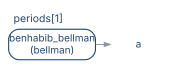

In [20]:
diagram_period(model, 1)

`diagram_trellis` draws the three latest periods, each framed with `h` and its age, economic time running from left to right. Each **inter-period connector** is a wire labeled with its index: `{a: m}` from one age's wealth at the continuation to the next age's wealth at the decision, and `{a: a_pre}` from the last age's wealth at the continuation to the wealth with which the bequest arrives.

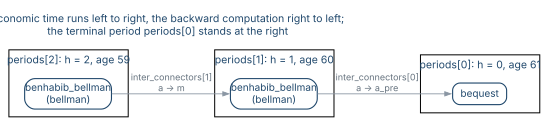

In [21]:
diagram_trellis(model, periods=[0, 1, 2])

## The same trellis in one call

`assemble_trellis` returns the trellis that the calls from `load_recipe` to `configure_trellis` make in their order; the next cell names its result `assembled`.

In [22]:
assembled = assemble_trellis("applications/benhabib-2019/declaration", "spec.yml")

`==` compares the two dictionaries, and so each stage occurrence by all its attributes, `provenance` among them:

In [23]:
assembled == model

True

## A fill

A **fill** is a dictionary bound to a slot by a keyword of `load_recipe`, each part going to the list of its kind. This one sets $\beta$ to 0.96 and `tol`, the tolerance of the endogenous-grid method, to `1e-10`, a value chosen only to show `configure_trellis` binding the settings again; the next cell names the result `filled`.

In [24]:
filled = load_recipe("applications/benhabib-2019/declaration", "spec.yml", fill={"calibration": {"β": 0.96}, "settings": {"tol": 1e-10}})

Given `filled`, `calibrate_trellis` binds again each occurrence whose calibration changed in a name it declares.

In [25]:
recalibrated = calibrate_trellis(model, filled)

Both stages declare $\beta$, so it bound every occurrence:

In [26]:
len(changed_positions(model, recalibrated))

37

`configure_trellis` then binds the settings.

In [27]:
model_b = configure_trellis(recalibrated, filled)

It bound every occurrence but the bequest, which has no settings:

In [28]:
len(changed_positions(recalibrated, model_b))

36

The occurrence at `periods[1]` holds the fill's values:

In [29]:
model_b["periods"][1]["stages"]["benhabib_bellman"].bindings

calibration   β = 0.96
              σ = 2.0
              μ = 0.5993
              A = 0.0006
              wage_fn = (8.222, 19.08, 26.78, 34.39, 42.96, 51.91, 61.65, 74.35, 93.42, 180.4)
              R_vec = (1.0011, 1.0094, 1.0258, 1.056, 1.0841)
              tau = 'q1'
              r_type = 'r1'
methods       policy                    !egm   block ../../methods/benhabib_bellman_egm.bl
              cntn_to_dcsn:Evaluation   !marginals   block ../../methods/marginals_benhabib_bellman.bl
settings      n_a        300     policy   !egm
              a_min      0.0     policy   !egm
              a_max      500.0   policy   !egm
              grid_phi   2.0
              tol        1e-10
              max_iter   500

The trellis `model` keeps its own $\beta$, since a verb returns new versions:

In [30]:
model["periods"][1]["stages"]["benhabib_bellman"].par["β"].value

0.97

## A sweep over the household's types

The paper solves one problem for each pair of a decile `tau` and a return type `r_type`. The calibration holds `q1` and `r1`; each other pair is a fill, and the family is a **sweep**, one trellis for each fill. The cells below compute three members one at a time, the first for the pair `q5` and `r3`.

In [31]:
swept = calibrate_trellis(model, load_recipe("applications/benhabib-2019/declaration", "spec.yml", fill={"calibration": {"tau": "q5", "r_type": "r3"}}))

It bound again the within-life occurrences and copied the bequest, which declares neither name:

In [32]:
len(changed_positions(model, swept))

36

The next cell reads the pair back from the occurrence at `periods[1]`.

In [33]:
swept["periods"][1]["stages"]["benhabib_bellman"].par

name     set                                              value                                                                   describes
β        (0, 1)                                           0.97
σ        ℝ₊                                               2.0
μ        ℝ₊                                               0.5993
A        ℝ₊                                               0.0006
wage_fn  ℝ₊ × ℝ₊ × ℝ₊ × ℝ₊ × ℝ₊ × ℝ₊ × ℝ₊ × ℝ₊ × ℝ₊ × ℝ₊  (8.222, 19.08, 26.78, 34.39, 42.96, 51.91, 61.65, 74.35, 93.42, 180.4)
R_vec    ℝ₊₊ × ℝ₊₊ × ℝ₊₊ × ℝ₊₊ × ℝ₊₊                      (1.0011, 1.0094, 1.0258, 1.056, 1.0841)
tau      Tau                                              q5
r_type   R_type                                           r3

The pair `q10` and `r5` binds the same occurrences:

In [34]:
len(changed_positions(model, calibrate_trellis(model, load_recipe("applications/benhabib-2019/declaration", "spec.yml", fill={"calibration": {"tau": "q10", "r_type": "r5"}}))))

36

The pair the file holds binds none:

In [35]:
len(changed_positions(model, calibrate_trellis(model, load_recipe("applications/benhabib-2019/declaration", "spec.yml", fill={"calibration": {"tau": "q1", "r_type": "r1"}}))))

0

## Two periods by accretion

A trellis is built backwards from an empty one by [[accretion-modules|accretion]]: `accrete` appends the period earlier in time with the inter-period connector to the period appended before it; the terminal period takes none. The next cell binds the bequest with the stage's own verbs.

In [36]:
bequest_by_hand = (elaborate_stage(load_stage("applications/benhabib-2019/declaration/stages/bequest/bequest.bl"))
                   .calibrate("applications/benhabib-2019/declaration/calibration/main.yml")
                   .methodize({})
                   .configure({}))

The last age of working life is calibrated with the calibration of `record`, since a verb binds one complete mapping.

In [37]:
age_60 = (elaborate_stage(load_stage("applications/benhabib-2019/declaration/stages/benhabib_bellman/benhabib_bellman.bl"))
          .calibrate(record["calibration"])
          .methodize("applications/benhabib-2019/declaration/stages/benhabib_bellman/methods.yml")
          .configure("applications/benhabib-2019/declaration/settings/default.yml"))

The terminal period is appended to the empty trellis first.

In [38]:
terminal = accrete({"periods": [], "inter_connectors": []}, {"stages": {"bequest": bequest_by_hand}, "connectors": []})

The period before it is appended with the inter-period connector `{a: a_pre}`.

In [39]:
by_hand = accrete(terminal, {"stages": {"benhabib_bellman": age_60}, "connectors": []}, {"a": "a_pre"})

Its occurrence at `periods[1]` prints the same sheet as the assembled trellis's occurrence there:

In [40]:
str(by_hand["periods"][1]["stages"]["benhabib_bellman"]) == str(assembled["periods"][1]["stages"]["benhabib_bellman"])

True

They are not equal by `==`, which also reads the provenance: the occurrence bound by hand records its methods and settings files by path and its calibration as a mapping in memory, with no source lists or active periods.

In [41]:
by_hand["periods"][1]["stages"]["benhabib_bellman"] == assembled["periods"][1]["stages"]["benhabib_bellman"]

False

Appending the same period again with the connector `{a: a}` joins nothing: `a` is not a field at which the period after it in time is entered, since its stage has no arrival perch and is entered at its decision wealth `m`. `accrete` appends the period and refuses nothing; the trellis's connection report records the unresolved endpoint and names the field to write.

In [42]:
twice = accrete(by_hand, {"stages": {"benhabib_bellman": age_60}, "connectors": []}, {"a": "a"})
[(item.rule, item.message) for item in connection_report(twice).selection.diagnostics]

[('endpoint-unresolved',
  "'a' names no arrival state field of periods[1] (the pair periods[2] → periods[1]); the arrival state fields there are m")]

The diagnostic names the field to write, `m`; the report calls the fields at which a period is entered its arrival state fields, whether or not its stage has an arrival perch. A period appended before a within-life age is therefore joined by `{a: m}`, as in the recipe's trellis, and the connector `{a: a_pre}` of the earlier cell joins the within-life period to the bequest, which arrives at `a_pre`. Built by hand or assembled from the registry through its recipe, the trellis holds the same stages at the same positions, and the two differ only in the provenance each occurrence records.